In [2]:
!python -m pip install --upgrade pip

In [3]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [4]:
#Pandas handles the dataset, Matplotlib/Seaborn create graphs, and Scikit-learn provides the train-test split, Decision Tree and evaluation functions.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import  precision_score, recall_score, f1_score

In [6]:
#This reads the CSV file and displays the first five rows.
data = pd.read_csv("loan_approval_dataset.csv")
data.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [7]:
#shape shows the number of rows and columns in the dataset.
data.shape

(4269, 13)

In [8]:
#Some column names contain extra spaces, so this line removes those spaces and makes the column names easier to use.
data.columns = data.columns.str.strip()
data.columns

Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='str')

In [9]:
#Machine Learning models need numerical values, so the three text columns are converted into 0 and 1.
data['education'] = data['education'].str.strip()
data['self_employed'] = data['self_employed'].str.strip()
data['loan_status'] = data['loan_status'].str.strip()

data['education'] = data['education'].map({'Graduate': 1, 'Not Graduate': 0})
data['self_employed'] = data['self_employed'].map({'Yes': 1, 'No': 0})
data['loan_status'] = data['loan_status'].map({'Approved': 1, 'Rejected': 0})
data.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,2,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,4,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


In [10]:
#This checks whether any column contains missing values.
data.isnull().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

In [11]:
#X contains the input features and y contains the output we want to predict. loan_id is removed because it is only an identifier.
X = data.drop(columns=['loan_id', 'loan_status'])
y = data['loan_status']

In [12]:
#80% of the data is used for training and 20% is used for testing. random_state=42 makes the split repeatable.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print('Training records:', len(X_train))
print('Testing records:', len(X_test))

Training records: 3415
Testing records: 854


In [13]:
# Create the three models
dt_model = DecisionTreeClassifier(random_state=42)
rf_model = RandomForestClassifier(random_state=42)
lr_model = LogisticRegression(max_iter=1000)

# Train the three models
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
lr_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [14]:
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
lr_pred = lr_model.predict(X_test)

In [15]:
dt_accuracy = accuracy_score(y_test, dt_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)
lr_accuracy = accuracy_score(y_test, lr_pred)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Decision Tree Accuracy: 97.78 %
Random Forest Accuracy: 98.01 %
Logistic Regression Accuracy: 79.86 %


In [16]:
results = pd.DataFrame({
    "Algorithm": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy,
        lr_accuracy
    ]
})
results

,Algorithm,Accuracy
0,Decision Tree,0.977752
1,Random Forest,0.980094
2,Logistic Regression,0.798595


In [17]:
print("Decision Tree Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

Decision Tree Confusion Matrix:
[[308  10]
 [  9 527]]

Random Forest Confusion Matrix:
[[308  10]
 [  7 529]]

Logistic Regression Confusion Matrix:
[[194 124]
 [ 48 488]]


In [18]:
new_applicant = pd.DataFrame({
    'no_of_dependents': [2],
    'education': [1],
    'self_employed': [0],
    'income_annum': [6000000],
    'loan_amount': [15000000],
    'loan_term': [15],
    'cibil_score': [750],
    'residential_assets_value': [5000000],
    'commercial_assets_value': [3000000],
    'luxury_assets_value': [10000000],
    'bank_asset_value': [5000000]
})

In [19]:
dt_prediction = dt_model.predict(new_applicant)[0]

rf_prediction = rf_model.predict(new_applicant)[0]

lr_prediction = lr_model.predict(new_applicant)[0]

print("Decision Tree:",
      "Approved" if dt_prediction == 1 else "Rejected")

print("Random Forest:",
      "Approved" if rf_prediction == 1 else "Rejected")

print("Logistic Regression:",
      "Approved" if lr_prediction == 1 else "Rejected")

Decision Tree: Approved
Random Forest: Approved
Logistic Regression: Approved


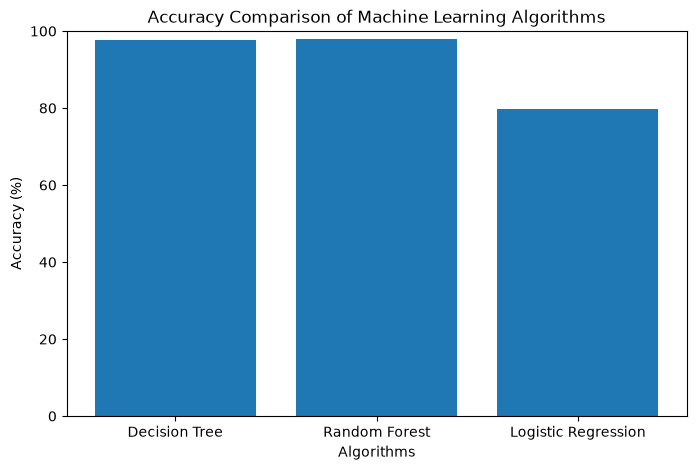

In [20]:
# Compare the accuracy of all three algorithms
algorithms = [
    "Decision Tree",
    "Random Forest",
    "Logistic Regression"
]
accuracies = [
    dt_accuracy * 100,
    rf_accuracy * 100,
    lr_accuracy * 100
]
plt.figure(figsize=(8, 5))
plt.bar(algorithms, accuracies)
plt.xlabel("Algorithms")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison of Machine Learning Algorithms")
plt.ylim(0, 100)
plt.show()

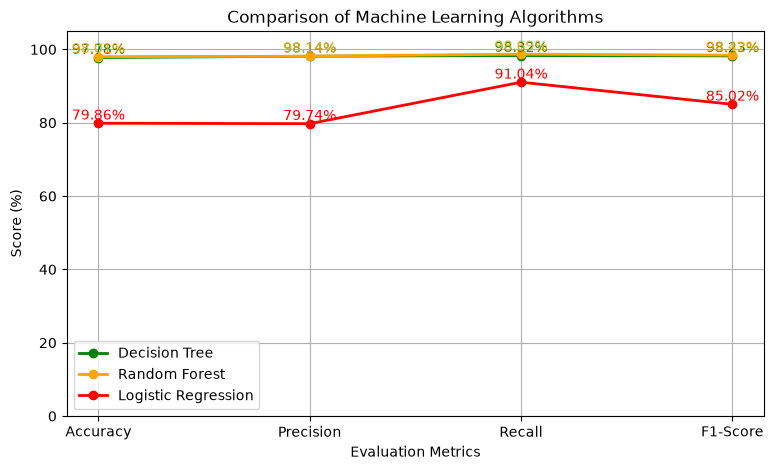

In [21]:
# Compare the three algorithms using multiple evaluation metrics
# Calculate metrics
dt_metrics = [
    accuracy_score(y_test, dt_pred) * 100,
    precision_score(y_test, dt_pred) * 100,
    recall_score(y_test, dt_pred) * 100,
    f1_score(y_test, dt_pred) * 100
]
rf_metrics = [
    accuracy_score(y_test, rf_pred) * 100,
    precision_score(y_test, rf_pred) * 100,
    recall_score(y_test, rf_pred) * 100,
    f1_score(y_test, rf_pred) * 100
]
lr_metrics = [
    accuracy_score(y_test, lr_pred) * 100,
    precision_score(y_test, lr_pred) * 100,
    recall_score(y_test, lr_pred) * 100,
    f1_score(y_test, lr_pred) * 100
]
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
plt.figure(figsize=(9, 5))
plt.plot(metrics, dt_metrics, marker='o',
         color='green', linewidth=2, label='Decision Tree')
plt.plot(metrics, rf_metrics, marker='o',
         color='orange', linewidth=2, label='Random Forest')
plt.plot(metrics, lr_metrics, marker='o',
         color='red', linewidth=2, label='Logistic Regression')
# Display values near the points
for i, value in enumerate(dt_metrics):
    plt.text(i, value + 1, f"{value:.2f}%", color='green', ha='center')
for i, value in enumerate(rf_metrics):
    plt.text(i, value + 1, f"{value:.2f}%", color='orange', ha='center')
for i, value in enumerate(lr_metrics):
    plt.text(i, value + 1, f"{value:.2f}%", color='red', ha='center')
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.title("Comparison of Machine Learning Algorithms")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.show()